# C09b — Cross-attack adaptation: NS10, RAFT and NS11

All five detectors; original **54 matched sources**, saved **20 exposed / 34 held-out** split. No texts are generated. RAFT means OG→RAFT; NS11 means RAFT(NS10).

Five highlighted pairs (defender exposure → evaluation text): **NS10→NS11, RAFT→NS11, NS11→NS11, NS11→NS10, NS11→RAFT**. We additionally score the full 3×3 adaptation matrix, frozen baselines and RAID-only controls to distinguish selective transfer from general recovery.

Run top to bottom in the existing project environment. Each detector has its own run cell; completed scores resume. Neural models load sequentially. Existing C08b/d adapted checkpoints are reused only after checking the shared split and exact training-text identities; if absent, continuation starts from the frozen model using the historical settings. Binoculars reuses saved two-component features/readouts (no Falcon inference); GLTR reuses saved rank features. Ghostbuster refits cheap heads on the common split, since C06c used a different split seed.

Interpretation: selective transfer can support **RAFT-associated shared detectable traces**. It cannot by itself prove the causal linguistic fingerprint or that the absence of band targeting caused it. Bootstrap intervals condition on one split, fitted models and human pool; they exclude training uncertainty.

In [1]:
from pathlib import Path
import os,sys,json,hashlib,tempfile,gc,copy,inspect,fcntl,contextlib,subprocess,random,math,time,warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch,transformers,joblib
from sklearn.base import clone
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.exceptions import ConvergenceWarning
from IPython.display import display
ROOT_OVERRIDE=None
ROOT=Path(ROOT_OVERRIDE).resolve() if ROOT_OVERRIDE else next((p for p in [Path.cwd().resolve(),*Path.cwd().resolve().parents,Path.home()/'Downloads/TemporalContextResearch/reproduction'] if (p/'results/causal/C05_Ghostbuster_RAID_fixed54').exists()),None)
assert ROOT is not None,'Set ROOT_OVERRIDE to your reproduction directory.'
R=ROOT/'results/causal'; BASE=R/'C02d2_fz118_ghostbuster_raid'; C05=R/'C05_Ghostbuster_RAID_fixed54'
OUT=R/'C09b_Cross_Attack_Adaptation_20_34_v1';OUT.mkdir(parents=True,exist_ok=True)
ARMS=['NS10','OG_RAFT','NS11']; DEFENDERS=['Frozen','RAID_only',*ARMS]
DETECTORS=['Ghostbuster','Binoculars','GLTR','RoBERTa','WaveDetect']
SEED=20260923; N_BOOT=5000
FOCAL=[('NS10','NS11'),('OG_RAFT','NS11'),('NS11','NS11'),('NS11','NS10'),('NS11','OG_RAFT')]
FILES={'NS10':R/'C06b_NEW_steps5_10_v1/NS10_texts.csv','OG_RAFT':R/'R01_published_local_v3/RAFT_adaptation20_34/RAFT_texts54.csv','NS11':R/'R11_NS10_RAFT_v1/NS11_texts.csv'}
OLD={'RoBERTa':R/'C08b_RoBERTa_competitors_RAFT_NS11_v1','WaveDetect':R/'C08d_WaveDetect_competitors_RAFT_NS11_v1','GLTR':R/'C08c_GLTR_competitors_RAFT_NS11_v1','Binoculars':R/'C08a_Binoculars_competitors_NF4_v1/RAFT_NS11_extension_v1'}
def sha(x):return hashlib.sha256(str(x).encode()).hexdigest()
def digest(x):return sha(json.dumps(x,sort_keys=True,ensure_ascii=False))
def file_sha(p):
 h=hashlib.sha256()
 with Path(p).open('rb') as f:
  for block in iter(lambda:f.read(1024*1024),b''):h.update(block)
 return h.hexdigest()
def read_json(p):return json.loads(Path(p).read_text()) if Path(p).exists() else None
def atomic_json(p,x):
 p=Path(p);p.parent.mkdir(parents=True,exist_ok=True);tmp=p.with_suffix(p.suffix+'.tmp');tmp.write_text(json.dumps(x,indent=2,sort_keys=True,allow_nan=False));os.replace(tmp,p)
def csv(f,p):
 p=Path(p);p.parent.mkdir(parents=True,exist_ok=True);tmp=p.with_suffix('.tmp');f.to_csv(tmp,index=False);os.replace(tmp,p)
def freeze(p,x):
 old=read_json(p)
 if old is not None:assert old==x,f'Changed scientific inputs: {p}; keep prior output and choose new OUT.'
 else:atomic_json(p,x)
def release():
 gc.collect()
 if torch.cuda.is_available():torch.cuda.empty_cache()
@contextlib.contextmanager
def run_lock():
 with (OUT/'run.lock').open('a') as f:
  fcntl.flock(f,fcntl.LOCK_EX|fcntl.LOCK_NB)
  try:yield
  finally:fcntl.flock(f,fcntl.LOCK_UN)
print('C09b output:',OUT)


/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


C09b output: ../results/causal/C09b_Cross_Attack_Adaptation_20_34_v1


In [2]:
meta=pd.read_parquet(BASE/'fz118_paired_features.parquet');corpus=pd.read_parquet(BASE/'paired_corpus.parquet')
raid=meta.loc[meta.dataset.eq('raid'),['source_id','split','label','domain']].merge(corpus[['source_id','text']],on='source_id',validate='one_to_one')
raid['text_sha']=raid.text.map(sha)
assert raid.groupby('text_sha').split.nunique().eq(1).all()
assert raid.assign(g=raid.source_id.str.split('__',n=1).str[-1]).groupby('g').split.nunique().eq(1).all()
frames={}
for arm,p in FILES.items():
 f=pd.read_csv(p,keep_default_na=False).sort_values('case_id').reset_index(drop=True)
 assert len(f)==54 and f.case_id.is_unique and f.source_id.is_unique and f.text.str.strip().ne('').all(),arm
 if 'text_sha' in f:assert f.text_sha.eq(f.text.map(sha)).all(),arm
 f=f[['case_id','source_id','domain','text']].copy();f['text_sha']=f.text.map(sha);f['arm']=arm;f['label']=1
 frames[arm]=f
ns=frames['NS10'];ids=ns.case_id.tolist();rm=raid.set_index('source_id')
assert rm.loc[ns.source_id,'split'].eq('test').all() and rm.loc[ns.source_id,'label'].eq(1).all()
for f in frames.values():
 assert f[['case_id','source_id','domain']].equals(ns[['case_id','source_id','domain']])
 assert f.domain.tolist()==rm.loc[f.source_id,'domain'].tolist()
split=read_json(R/'C07b_RoBERTa_RAID_OG_NS10_v1/adaptation20_34_seed20260923/split.json')
assert split is not None,'Restore the original shared 20/34 split.'
chosen=sorted(split['adaptation_cases']);held=sorted(split['test_cases'])
assert len(chosen)==20 and len(held)==34 and not set(chosen)&set(held) and set(chosen+held)==set(ids)
train=raid.loc[raid.split.eq('train')].sort_values('source_id').reset_index(drop=True)
validation=raid.loc[raid.split.eq('validation')].sort_values('source_id').reset_index(drop=True)
humans=raid.loc[raid.label.eq(0)&raid.split.isin(['validation','test'])].assign(arm='Human',case_id='').copy()
held_frames={a:f.set_index('case_id').loc[held].reset_index() for a,f in frames.items()}
evaldocs=pd.concat([humans,*held_frames.values()],ignore_index=True)
for a,f in frames.items():
 fit=pd.concat([train,f.loc[f.case_id.isin(chosen)]])
 assert not set(fit.text_sha)&set(pd.concat([validation,evaldocs]).text_sha),a
freeze(OUT/'inputs.json',dict(split=split,texts={a:f[['case_id','source_id','domain','text_sha']].to_dict('records') for a,f in frames.items()},raid=raid[['source_id','split','label','text_sha']].to_dict('records')))
csv(ns[['case_id','source_id','domain']].assign(role=np.where(ns.case_id.isin(chosen),'adaptation','heldout')),OUT/'case_roles.csv')
# This audit inspects local weights; GitHub often excludes large checkpoint files.
audit=[]
for a in ['RAID_only',*ARMS]:
 rp=OLD['RoBERTa']/'adaptation'/a/'best_model'
 wp=OLD['WaveDetect']/('RAID_only_continuation' if a=='RAID_only' else a)/'best.pt'
 audit += [dict(detector='RoBERTa',exposure=a,checkpoint=str(rp),available=(rp/'config.json').exists()),dict(detector='WaveDetect',exposure=a,checkpoint=str(wp),available=wp.exists())]
display(pd.DataFrame(audit));csv(pd.DataFrame(audit),OUT/'checkpoint_inventory.csv')
del meta,corpus,rm;release()


,detector,exposure,checkpoint,available
0,RoBERTa,RAID_only,/home/user/Downloads/TemporalContextResearch/...,True
1,WaveDetect,RAID_only,/home/user/Downloads/TemporalContextResearch/...,True
2,RoBERTa,NS10,/home/user/Downloads/TemporalContextResearch/...,True
3,WaveDetect,NS10,/home/user/Downloads/TemporalContextResearch/...,True
4,RoBERTa,OG_RAFT,/home/user/Downloads/TemporalContextResearch/...,True
5,WaveDetect,OG_RAFT,/home/user/Downloads/TemporalContextResearch/...,True
6,RoBERTa,NS11,/home/user/Downloads/TemporalContextResearch/...,True
7,WaveDetect,NS11,/home/user/Downloads/TemporalContextResearch/...,True


## Shared evaluation and plots
Every defender rescored against the same test-human IDs. AUROC is genre-weighted; thresholds come only from validation humans. Full matrices and five-pair staircases are saved after each detector. Recovery is measured against both frozen and RAID-only control. Selectivity contrasts subtract recovery on the other target arm, paired by source. Intervals are exploratory, pointwise 95% intervals (no multiplicity correction).

In [3]:
def aligned_features(base,features,cols,key='text_sha'):
 assert key in features and all(c in features for c in cols)
 small=features[[key,*cols]].copy()
 # Repeated shared texts may appear under different arms; their features must agree.
 for c in cols:assert small.groupby(key)[c].nunique(dropna=False).le(1).all(),c
 small=small.drop_duplicates(key).set_index(key)
 assert set(base[key])<=set(small.index),'Missing saved features: restore completed C08 feature exports.'
 x=small.loc[base[key],cols].to_numpy(float);assert np.isfinite(x).all()
 return x

def save_scores(det,defender,frame,values,provenance):
 f=frame.drop(columns='text',errors='ignore').copy();f['AI_score']=np.asarray(values,float)
 assert np.isfinite(f.AI_score).all() and len(f)==len(evaldocs)
 folder=OUT/det/defender;folder.mkdir(parents=True,exist_ok=True)
 freeze(folder/'provenance.json',provenance);csv(f,folder/'scores.csv')

def summarize(det):
 folder=OUT/det;rows=[];stairs=[];contrib={};ops=[]
 mix=ns.set_index('case_id').loc[held].domain.value_counts(normalize=True)
 for defender in DEFENDERS:
  scores=pd.read_csv(folder/defender/'scores.csv',keep_default_na=False)
  h=scores.loc[scores.arm.eq('Human')].copy();refs={}
  for sp in ['validation','test']:
   q=h.loc[h.split.eq(sp)&h.domain.isin(mix.index)].copy()
   expected=humans.loc[humans.split.eq(sp)&humans.domain.isin(mix.index),'source_id']
   assert q.source_id.is_unique and set(q.source_id)==set(expected)
   counts=q.domain.value_counts();assert set(mix.index)<=set(counts.index)
   q['weight']=q.domain.map(mix)/q.domain.map(counts);refs[sp]=q
  v,h=refs['validation'],refs['test'];vs=v.AI_score.to_numpy();hs=h.AI_score.to_numpy();w=h.weight.to_numpy()
  for a in ARMS:
   f=scores.loc[scores.arm.eq(a)].set_index('case_id').loc[held]
   assert len(f)==34 and f.text_sha.tolist()==held_frames[a].text_sha.tolist()
   ai=f.AI_score.to_numpy();c=((ai[:,None]>hs)+.5*(ai[:,None]==hs))@w;contrib[defender,a]=c
   rows.append(dict(detector=det,exposure=defender,arm=a,cases=34,AUROC=float(c.mean()),mean_AI_score=float(ai.mean())))
   cuts=np.r_[np.inf,np.unique(vs)[::-1],-np.inf]
   st=pd.DataFrame(dict(detector=det,exposure=defender,arm=a,threshold=cuts,calibration_FPR=[v.weight.to_numpy()[vs>x].sum() for x in cuts],test_FPR=[w[hs>x].sum() for x in cuts],TPR=[(ai>x).mean() for x in cuts]))
   stairs.append(st)
   for target in [0,.001,.005,.01,.02,.05,.1,.2,.5,1]:
    op=st.loc[st.calibration_FPR<=target+1e-12].iloc[-1].to_dict();ops.append(dict(target_FPR=target,**op))
 ix=np.random.default_rng(SEED).integers(0,34,(N_BOOT,34));changes=[]
 def contrast(name,d):
  lo,hi=np.quantile(d[ix].mean(1),[.025,.975]);changes.append(dict(detector=det,contrast=name,delta_AUROC=float(d.mean()),ci_low=float(lo),ci_high=float(hi)))
 for d in ARMS:
  for a in ARMS:
   for ref in ['Frozen','RAID_only']:contrast(f'{d} exposure on {a} minus {ref}',contrib[d,a]-contrib[ref,a])
 contrast('RAFT vs NS10 exposure on NS11',contrib['OG_RAFT','NS11']-contrib['NS10','NS11'])
 for d in ['OG_RAFT','NS11']:
  for a in ['OG_RAFT','NS11']:
   if d==a:continue
   contrast(f'{d} exposure: recovery on {a} minus recovery on NS10',(contrib[d,a]-contrib['RAID_only',a])-(contrib[d,'NS10']-contrib['RAID_only','NS10']))
 summary=pd.DataFrame(rows);st=pd.concat(stairs,ignore_index=True)
 csv(summary,folder/'summary.csv');csv(st,folder/'staircases.csv');csv(pd.DataFrame(ops),folder/'operating_points.csv');csv(pd.DataFrame(changes),folder/'paired_contrasts.csv')
 ctab=pd.DataFrame([dict(exposure=d,arm=a,case_id=cid,auc_contribution=float(x)) for (d,a),values in contrib.items() for cid,x in zip(held,values)])
 csv(ctab,folder/'case_auc_contributions.csv')
 display(summary.pivot(index='exposure',columns='arm',values='AUROC').reindex(DEFENDERS)[ARMS].round(4))
 display(pd.DataFrame(changes).tail(3).round(5))
 fig,axs=plt.subplots(1,2,figsize=(12,4))
 mat=summary.pivot(index='exposure',columns='arm',values='AUROC').reindex(DEFENDERS)[ARMS]
 for ax,data,title,cmap,lo,hi in [(axs[0],mat,'Held-out AUROC','viridis',0,1),(axs[1],mat.loc[ARMS]-mat.loc['RAID_only'],'Recovery over RAID-only','coolwarm',-.5,.5)]:
  im=ax.imshow(data,vmin=lo,vmax=hi,cmap=cmap,aspect='auto');ax.set_xticks(range(3),ARMS);ax.set_yticks(range(len(data)),data.index);ax.set_title(title);ax.set_xlabel('Evaluation text');ax.set_ylabel('Exposure arm')
  for i in range(len(data)):
   for j in range(3):ax.text(j,i,f'{data.iloc[i,j]:.3f}',ha='center',va='center',color='white' if abs(data.iloc[i,j])>.65 else 'black')
  fig.colorbar(im,ax=ax)
 fig.suptitle(det+' — common 20/34 split');fig.tight_layout()
 for ext in ['png','pdf']:fig.savefig(folder/('matrix.'+ext),bbox_inches='tight',dpi=170)
 plt.show();plt.close(fig)
 colors=dict(zip(ARMS,['#209675','#009EAA','#553399']))
 # One combined plot: color denotes target text; style denotes defender exposure.
 fig,axes=plt.subplots(1,3,figsize=(19,6));styles={'Frozen':':','NS10':'--','OG_RAFT':'-.','NS11':'-'}
 pairs=[('Frozen',a) for a in ARMS]+FOCAL
 for ax,xmax in zip(axes,[100,20,6]):
  for d,a in pairs:
   q=st.loc[st.exposure.eq(d)&st.arm.eq(a)];val=float(mat.loc[d,a])
   ax.step(q.test_FPR*100,q.TPR*100,where='post',color=colors[a],ls=styles[d],label=f'{a} / {d} exposure ({val:.3f})')
  ax.plot([0,xmax],[0,xmax],color='gray',ls=':');ax.set(xlim=(0,xmax),ylim=(0,100),xlabel='Realized test-human FPR (%)',ylabel='AI TPR (%)');ax.grid(alpha=.2)
 handles,labels=axes[0].get_legend_handles_labels();fig.legend(handles,labels,loc='lower center',ncol=4,bbox_to_anchor=(.5,-.1));fig.suptitle(det+' — five focal comparisons with matched frozen baselines');fig.tight_layout()
 for ext in ['png','pdf']:fig.savefig(folder/('five_pairs_staircases.'+ext),bbox_inches='tight',dpi=170)
 plt.show();plt.close(fig)
 return summary


## Binoculars — reuse component scores and adapted readouts
No Falcon models load here. Reads the completed C08a RAFT/NS11 extension. Reuses saved readouts only when their split and training manifest agree; missing/incompatible readouts are fitted on CPU with the original train-only scaler.

Binoculars RAID_only : reused saved readout
Binoculars NS10 : reused saved readout
Binoculars OG_RAFT : reused saved readout
Binoculars NS11 : reused saved readout


arm,NS10,OG_RAFT,NS11
exposure,,,
Frozen,0.6843,0.7129,0.5087
RAID_only,0.6721,0.7056,0.4433
NS10,0.6782,0.7134,0.4587
OG_RAFT,0.6791,0.7151,0.4635
NS11,0.6946,0.7359,0.5171


,detector,contrast,delta_AUROC,ci_low,ci_high
18,Binoculars,RAFT vs NS10 exposure on NS11,0.00478,0.00242,0.00754
19,Binoculars,OG_RAFT exposure: recovery on NS11 minus recov...,0.01313,0.00492,0.02177
20,Binoculars,NS11 exposure: recovery on OG_RAFT minus recov...,0.00772,-0.00729,0.02302


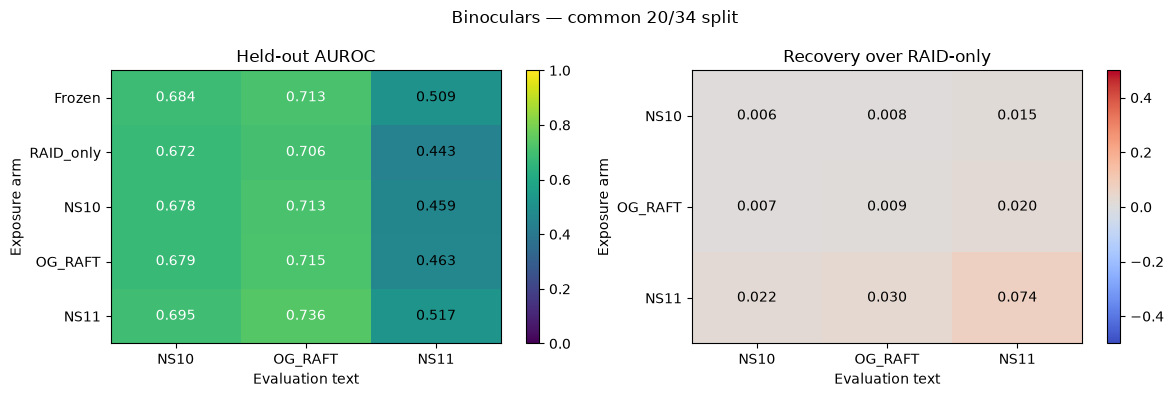

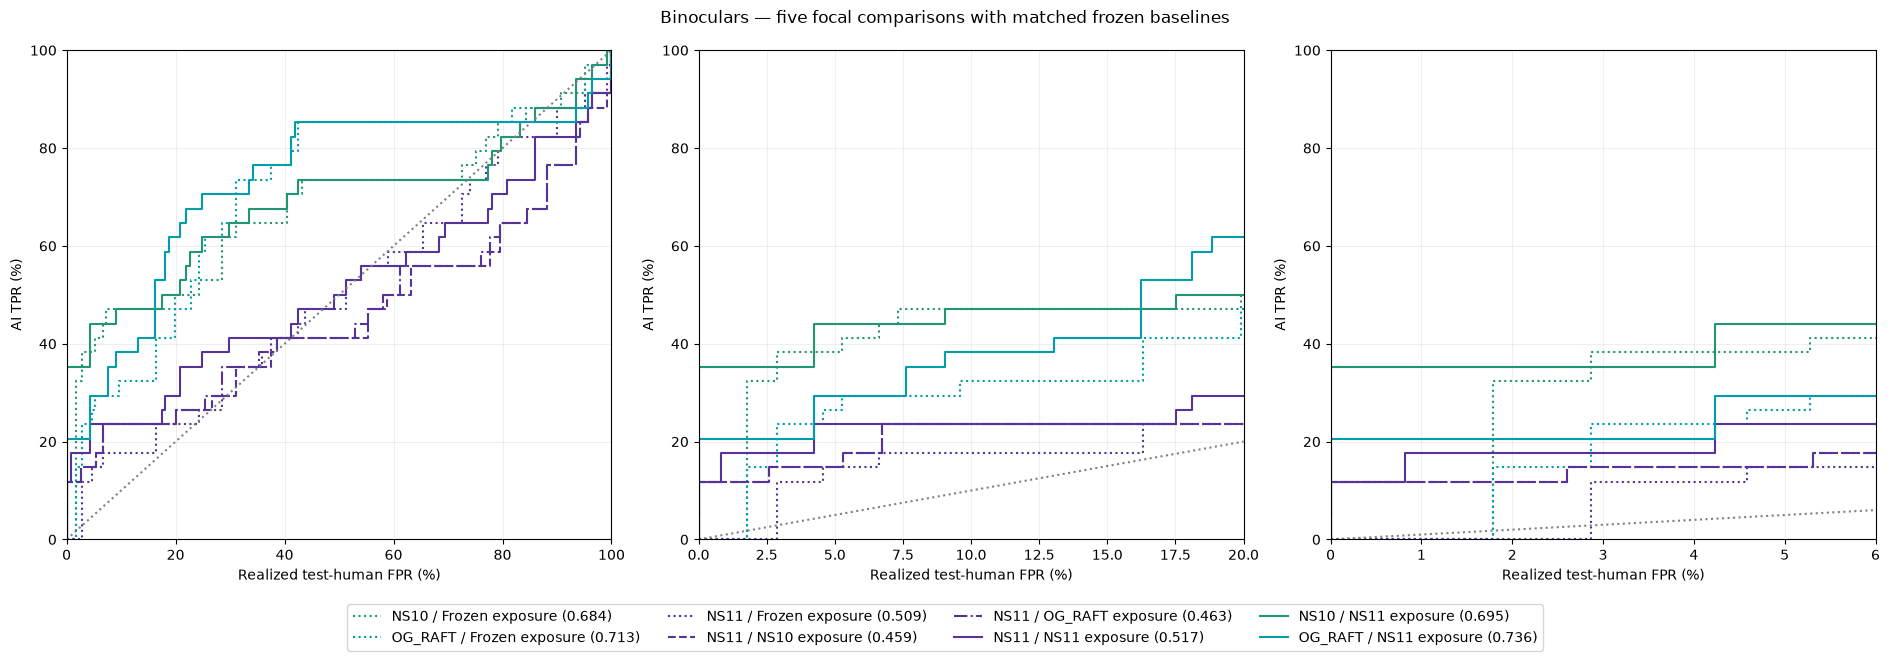

In [4]:
def run_binoculars():
 det='Binoculars';old=OLD[det];cols=['mean_nll','cross_entropy']
 allf=pd.read_csv(old/'all_scores.csv',keep_default_na=False)
 X=aligned_features(evaldocs,allf,cols)
 T=allf.loc[allf.stage.eq('RAID_train')].copy()
 assert T.source_id.is_unique and set(T.source_id)==set(train.source_id)
 T=T.set_index('source_id').loc[train.source_id].reset_index();assert T.text_sha.tolist()==train.text_sha.tolist()
 scaler=StandardScaler().fit(T[cols]);base=LogisticRegression(C=1.,class_weight='balanced',solver='lbfgs',max_iter=5000,random_state=SEED)
 signature=file_sha(old/'all_scores.csv')
 save_scores(det,'Frozen',evaldocs,-X[:,0]/X[:,1],dict(features=signature,score='negative mean_nll / cross_entropy'))
 for d in ['RAID_only',*ARMS]:
  extra=frames[d].loc[frames[d].case_id.isin(chosen)] if d in ARMS else None
  fit=T[cols].to_numpy();y=T.label.astype(int).to_numpy()
  if extra is not None:fit=np.vstack([fit,aligned_features(extra,allf,cols)]);y=np.r_[y,np.ones(20,int)]
  path=old/('RAID_only_readout.joblib' if d=='RAID_only' else d+'/adapted_readout.joblib');head=None
  if path.exists():
   saved=joblib.load(path);p=saved['protocol']
   ok=set(p['adaptation_cases'])==set(chosen) and set(p['test_cases'])==set(held) and p['features']==cols
   ok=ok and np.allclose(saved['scaler'].mean_,scaler.mean_) and np.allclose(saved['scaler'].scale_,scaler.scale_)
   if ok and d in ARMS:
    manifest=pd.read_csv(old/d/'training_manifest.csv',keep_default_na=False)
    ok=sorted(manifest.text_sha.tolist())==sorted(train.text_sha.tolist()+extra.text_sha.tolist())
   if ok:head=saved['model'];print(det,d,': reused saved readout')
  if head is None:
   with warnings.catch_warnings():
    warnings.simplefilter('error',ConvergenceWarning);head=clone(base).fit(scaler.transform(pd.DataFrame(fit,columns=cols)),y)
   print(det,d,': fitted CPU readout')
  local=OUT/det/d;local.mkdir(parents=True,exist_ok=True);joblib.dump(dict(model=head,scaler=scaler),local/'readout.joblib')
  save_scores(det,d,evaldocs,head.decision_function(scaler.transform(pd.DataFrame(X,columns=cols))),dict(features=signature,model=file_sha(local/'readout.joblib'),exposure=d))
 return summarize(det)
with run_lock():run_binoculars()


## GLTR — reuse saved rank features; cheap classifier refits
The original C07c scaler and classifier parameters are retained. Refitting the small heads gives an exact shared-split training manifest without loading GPT-2.

arm,NS10,OG_RAFT,NS11
exposure,,,
Frozen,0.5083,0.3557,0.1039
RAID_only,0.5083,0.3557,0.1039
NS10,0.5099,0.3692,0.1085
OG_RAFT,0.5027,0.4082,0.1297
NS11,0.4984,0.4520,0.1536


,detector,contrast,delta_AUROC,ci_low,ci_high
18,GLTR,RAFT vs NS10 exposure on NS11,0.0212,0.01394,0.02913
19,GLTR,OG_RAFT exposure: recovery on NS11 minus recov...,0.0315,0.01768,0.04569
20,GLTR,NS11 exposure: recovery on OG_RAFT minus recov...,0.1062,0.07187,0.13924


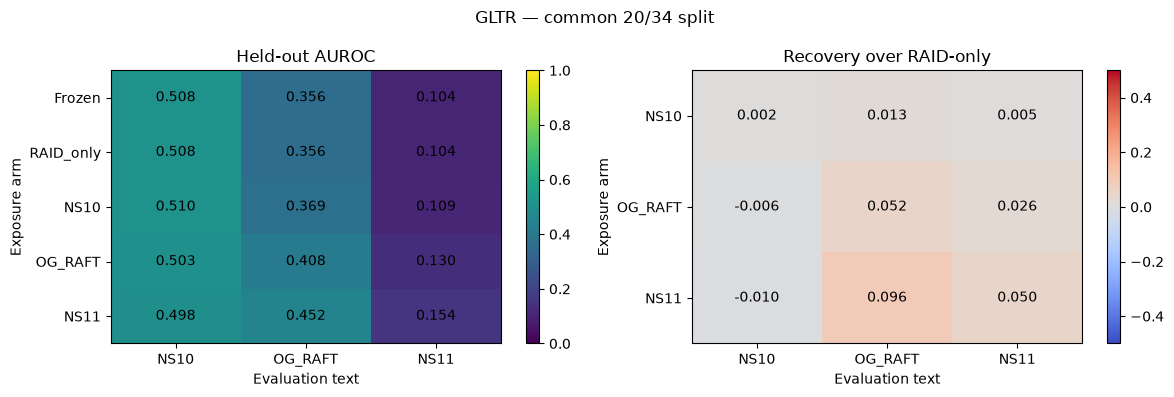

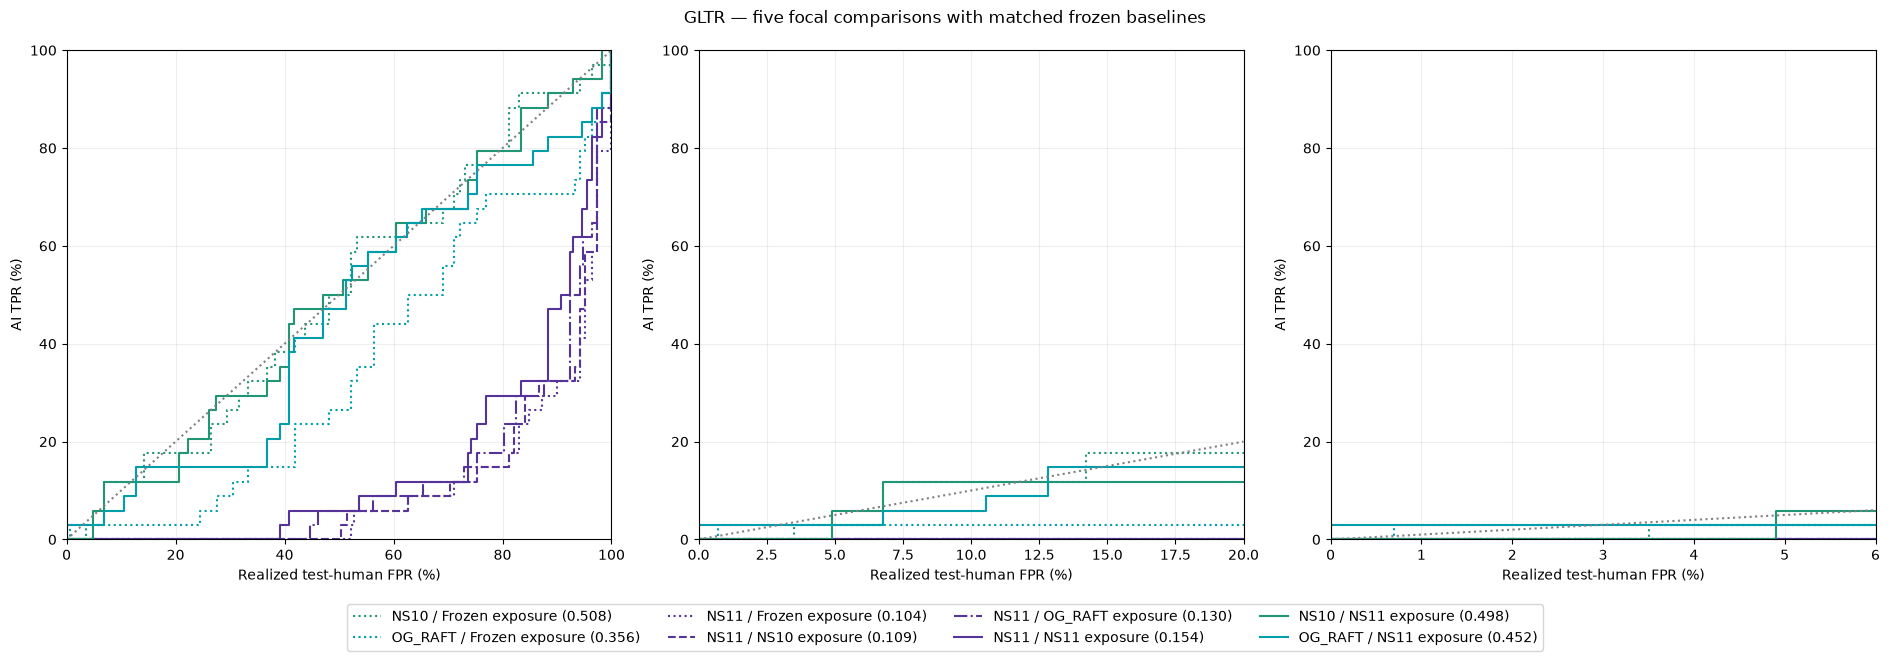

In [5]:
def run_gltr():
 det='GLTR';old=OLD[det];cols=['rank_1_10','rank_11_100','rank_101_1000','rank_gt_1000']
 paths=[old/'RAID_train_features.csv',old/'human_features.csv',*[old/'features_export'/(a+'.csv') for a in ARMS]]
 feats=pd.concat([pd.read_csv(p,keep_default_na=False) for p in paths],ignore_index=True)
 bundle=joblib.load(R/'C07c_GLTR_RAID_OG_NS10_v1/classifiers.joblib');scaler=bundle['scaler'];base=bundle['heads']['Frozen / RAID-only'];assert bundle['features']==cols
 X=scaler.transform(pd.DataFrame(aligned_features(evaldocs,feats,cols),columns=cols));T=scaler.transform(pd.DataFrame(aligned_features(train,feats,cols),columns=cols))
 provenance=dict(features={p.name:file_sha(p) for p in paths},classifier=file_sha(R/'C07c_GLTR_RAID_OG_NS10_v1/classifiers.joblib'))
 for d in DEFENDERS:
  head=base
  if d in ARMS:
   extra=frames[d].loc[frames[d].case_id.isin(chosen)].sort_values('case_id')
   Z=scaler.transform(pd.DataFrame(aligned_features(extra,feats,cols),columns=cols))
   with warnings.catch_warnings():
    warnings.simplefilter('error',ConvergenceWarning);head=clone(base).fit(np.vstack([T,Z]),np.r_[train.label.to_numpy(int),np.ones(20,int)])
  local=OUT/det/d;local.mkdir(parents=True,exist_ok=True);joblib.dump(head,local/'head.joblib')
  save_scores(det,d,evaldocs,head.decision_function(X),dict(**provenance,head=file_sha(local/'head.joblib'),exposure=d,control='frozen is original RAID-only fit'))
 return summarize(det)
with run_lock():run_gltr()


## Ghostbuster — frozen 14-feature extractor, shared-split adapted heads
The C08/C08e feature caches are reused when contracts match. Missing features are extracted with the pinned surrogate LMs sequentially. Three small calibrated heads are fitted on original RAID training plus the corresponding twenty texts; no symbolic-feature search is repeated.

In [6]:
GB_EXTRACTOR_SOURCE = 'class FrozenGhostbuster:\n    """C05 representation and classifier; never fits or selects any feature."""\n    def __init__(self):\n        self.contract=read_json(C05/\'contract.json\')\n        commit=self.contract[\'official_code_commit\']\n        def head(p):\n            try:return subprocess.check_output([\'git\',\'-C\',str(p),\'rev-parse\',\'HEAD\'],text=True,stderr=subprocess.DEVNULL).strip()\n            except (OSError,subprocess.CalledProcessError):return None\n        self.code=next((p for p in [ROOT.parent/\'data/external/ghostbuster\',ROOT/\'data/external/ghostbuster\',\n            ROOT/\'data/external/ghostbuster-code\'] if (p/\'utils/symbolic.py\').exists() and head(p)==commit),None)\n        assert self.code is not None, \'Restore the exact Ghostbuster source checkout used by C05.\'\n        sys.path.insert(0,str(self.code))\n        import utils.symbolic as sym\n        from utils.featurize import t_featurize_logprobs, normalize\n        assert Path(sym.__file__).resolve().is_relative_to(self.code.resolve()), \'Restart kernel: conflicting utils module.\'\n        self.sym=sym;self.manual=t_featurize_logprobs;self.normalize=normalize\n        with (C05/\'ghostbuster_frozen.pkl\').open(\'rb\') as f:self.model=gb_pickle.load(f)\n        self.mu=np.load(C05/\'mu.npy\');self.sigma=np.load(C05/\'sigma.npy\')\n        self.names=read_json(C05/\'feature_names.json\')\n        self.selected=[s for s in (C05/\'selected_features.txt\').read_text().splitlines() if s.strip()]\n        assert self.names==self.contract[\'manual_features\']+self.selected and len(self.names)==14\n        assert list(self.model.classes_)==[0,1]\n        self.limit=int(self.contract[\'max_tokens\']);self.enc=tiktoken.encoding_for_model(\'davinci\')\n        self.ids={k:self.contract[\'stream_mapping\'][k+\'-logprobs\'] for k in [\'ada\',\'davinci\']}\n        self.tok=AutoTokenizer.from_pretrained(self.ids[\'ada\'],revision=pin(self.ids[\'ada\']))\n        for s in [\'Hello world\'," can\'t won\'t 123",\'First\\nSecond\']:\n            assert self.tok.encode(s,add_special_tokens=False)==self.enc.encode(s)\n        self.old={k:pd.read_parquet(C05/f\'cache/{k}_surrogate_probs.parquet\').set_index(\'text_sha\').probs.to_dict()\n                  for k in [\'ada\',\'davinci\']}\n        self.ng=pd.read_parquet(C05/\'cache/ngram_probs_v2.parquet\').set_index(\'text_sha\')\n        self.rf=pd.read_parquet(C05/\'raid_all_features.parquet\').set_index(\'doc_key\')\n        assert set(self.rf.index)==set(\'raid::\'+raid.source_id.astype(str))\n        self.spec=dict(frozen=FROZEN_HASHES,max_tokens=self.limit,dtype=\'float16\',version=\'C08_stream_v1\')\n        freeze(OUT/\'ghostbuster_contract.json\',self.spec)\n        # Saved originals spanning three lengths validate tokenization and all 14 features.\n        sent=og.assign(n=og.text.map(lambda s:len(self.enc.encode(s)))).sort_values(\'n\')\n        self.sentinels=sent.iloc[[0,len(sent)//2,len(sent)-1]].to_dict(\'records\')\n        self.trigram=None\n        for r in self.sentinels:\n            h=r[\'text_sha\']; assert h in self.ng.index and all(h in self.old[k] for k in self.old)\n            v=self.vector(r[\'text\'],self.old[\'ada\'][h],self.old[\'davinci\'][h],\n                          self.ng.loc[h,\'trigram\'],self.ng.loc[h,\'unigram\'])\n            np.testing.assert_allclose(v,self.rf.loc[\'raid::\'+r[\'source_id\'],self.names].to_numpy(float),rtol=1e-7,atol=1e-9)\n        self.raid_scores=self.predict(self.rf.loc[\'raid::\'+raid.source_id.astype(str),self.names].to_numpy(float))\n        print(\'C05 cached streams reproduce all 14 features on three historical sentinels.\')\n    def predict(self,v):return self.model.predict_proba(self.normalize(np.asarray(v,float),mu=self.mu,sigma=self.sigma))[:,1]\n    def vector(self,text,ada,dav,tri,uni):\n        vm=dict(zip([\'ada-logprobs\',\'davinci-logprobs\',\'trigram-logprobs\',\'unigram-logprobs\'],\n                    [np.asarray(x,float) for x in [ada,dav,tri,uni]]))\n        assert len({len(v) for v in vm.values()})==1\n        ids=self.enc.encode(text)[:self.limit]\n        manual=self.manual(vm[\'davinci-logprobs\'],vm[\'ada-logprobs\'],self.tok.convert_ids_to_tokens(ids))\n        def ev(exp):\n            parts=self.sym.get_words(exp);v=vm[parts[0]];i=1\n            while i<len(parts):\n                if parts[i] in self.sym.vec_functions:\n                    v=self.sym.vec_functions[parts[i]](v,vm[parts[i+1]]);i+=2\n                elif parts[i] in self.sym.scalar_functions:return float(self.sym.scalar_functions[parts[i]](v))\n                else:raise ValueError(exp)\n            raise ValueError(exp)\n        v=np.asarray(list(manual)+[ev(e) for e in self.selected],float)\n        assert v.shape==(14,) and np.isfinite(v).all()\n        return v\n    def path(self,text,kind):return OUT/\'cache/ghostbuster\'/digest([self.spec,kind,sha(text)])\n    def neural(self,lm,text):\n        ids=self.enc.encode(text)[:self.limit]\n        x=torch.tensor([[50256]+ids],device=DEVICE)\n        with torch.inference_mode():\n            logits=lm(x).logits[0,:-1,:]\n            p=torch.exp(logits.gather(1,x[0,1:,None]).squeeze(1)-torch.logsumexp(logits,dim=-1)).float().cpu().numpy()\n        assert len(p)>0 and np.isfinite(p).all()\n        return p.tolist()\n    def score(self,texts,purpose=\'evaluation\'):\n        texts=list(map(str,texts));assert all(t.strip() for t in texts), \'Empty output cannot silently become OG.\'\n        unique=list(dict.fromkeys(texts));vectors={};todo=[]\n        for t in unique:\n            old=read_json(self.path(t,\'features\'))\n            if old is None:todo.append(t)\n            else:vectors[t]=old[\'features\']\n        streams={k:{} for k in [\'ada\',\'davinci\',\'trigram\',\'unigram\']}\n        for kind in [\'ada\',\'davinci\']:\n            missing=[]\n            for t in todo:\n                h=sha(t);p=self.path(t,kind);old=read_json(p)\n                if old is not None:streams[kind][t]=old\n                elif h in self.old[kind]:streams[kind][t]=list(map(float,self.old[kind][h]))\n                else:missing.append(t)\n            if missing:\n                clean_memory()\n                lm=AutoModelForCausalLM.from_pretrained(self.ids[kind],revision=pin(self.ids[kind]),\n                    torch_dtype=torch.float16,low_cpu_mem_usage=True).to(DEVICE).eval()\n                try:\n                    for r in self.sentinels:\n                        np.testing.assert_allclose(self.neural(lm,r[\'text\']),self.old[kind][r[\'text_sha\']],rtol=.002,atol=5e-5)\n                    for i,t in enumerate(missing,1):\n                        value=self.neural(lm,t);atomic_json(self.path(t,kind),value);streams[kind][t]=value\n                        if i==1 or i%16==0:print(f\'Ghostbuster {purpose}: {kind} {i}/{len(missing)}\',flush=True)\n                finally:del lm;clean_memory()\n        if todo and self.trigram is None:\n            try:\n                with (self.code/\'model/trigram_model.pkl\').open(\'rb\') as f:self.trigram=gb_pickle.load(f)\n                self.trigram.n_gram_probability((50256,50256,100))\n            except Exception:\n                nltk.data.find(\'corpora/brown\');self.trigram=self.sym.train_trigram(verbose=True)\n            for r in self.sentinels:\n                tri,uni=self.ngrams(r[\'text\'])\n                np.testing.assert_allclose(tri,self.ng.loc[r[\'text_sha\'],\'trigram\'],rtol=1e-6,atol=1e-10)\n                np.testing.assert_allclose(uni,self.ng.loc[r[\'text_sha\'],\'unigram\'],rtol=1e-6,atol=1e-10)\n        for t in todo:\n            h=sha(t)\n            if h in self.ng.index:tri,uni=self.ng.loc[h,\'trigram\'],self.ng.loc[h,\'unigram\']\n            else:tri,uni=self.ngrams(t)\n            v=self.vector(t,streams[\'ada\'][t],streams[\'davinci\'][t],tri,uni)\n            vectors[t]=v.tolist();atomic_json(self.path(t,\'features\'),dict(text_sha=h,features=v.tolist()))\n        scores=self.predict([vectors[t] for t in texts])\n        # Logs detector usage without sharing any other detector or held-out human reference.\n        audit=dict(purpose=purpose,text_hashes=[sha(t) for t in texts],scores=scores.tolist())\n        atomic_json(OUT/\'cache/ghostbuster_queries\'/f\'{digest(audit)}.json\',audit)\n        return scores\n    def ngrams(self,text):\n        ids=self.enc.encode(text)[:self.limit];pad=[50256,50256]+ids\n        tri=np.asarray([self.trigram.n_gram_probability(tuple(pad[i:i+3])) for i in range(len(ids))],np.float32)\n        uni=np.asarray([self.trigram.base.n_gram_probability((t,)) for t in ids],np.float32)\n        return tri,uni'


C05 cached streams reproduce all 14 features on three historical sentinels.


/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  w

arm,NS10,OG_RAFT,NS11
exposure,,,
Frozen,0.4961,0.2817,0.1562
RAID_only,0.4961,0.2817,0.1562
NS10,0.5741,0.3345,0.2460
OG_RAFT,0.5535,0.3999,0.3003
NS11,0.6136,0.4412,0.4077


,detector,contrast,delta_AUROC,ci_low,ci_high
18,Ghostbuster,RAFT vs NS10 exposure on NS11,0.05429,0.03286,0.07711
19,Ghostbuster,OG_RAFT exposure: recovery on NS11 minus recov...,0.08666,0.03663,0.13769
20,Ghostbuster,NS11 exposure: recovery on OG_RAFT minus recov...,0.04198,-0.02552,0.10860


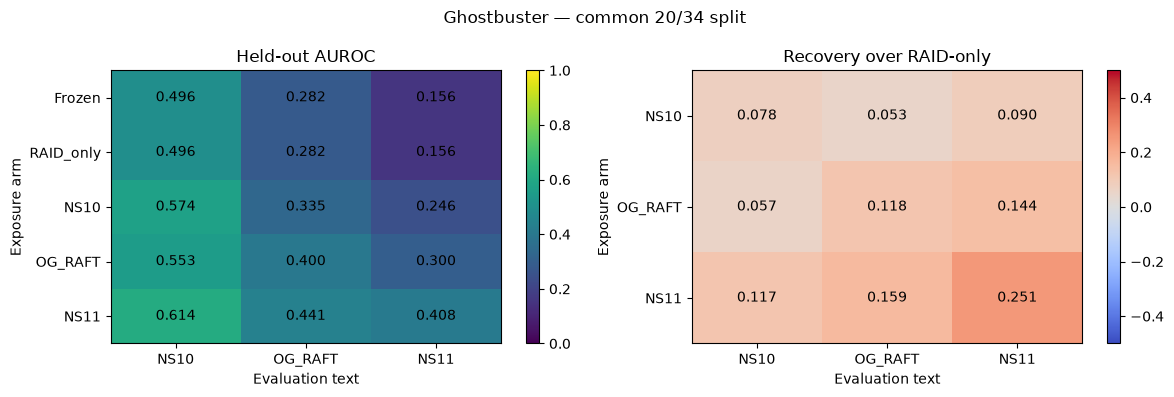

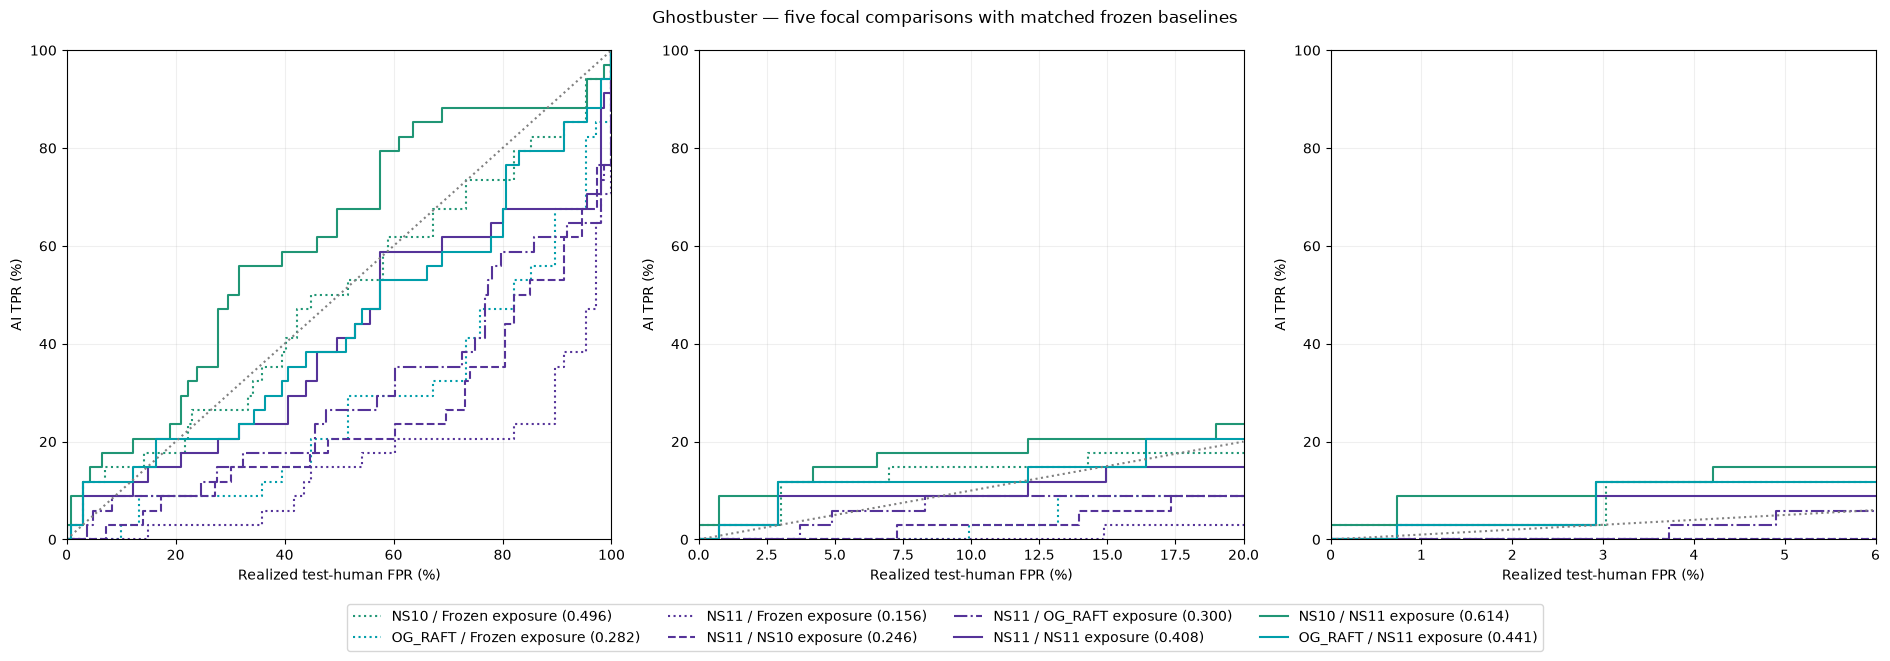

In [7]:
def run_ghostbuster():
 import dill as gb_pickle,tiktoken,nltk
 from transformers import AutoTokenizer,AutoModelForCausalLM
 det='Ghostbuster';folder=OUT/det;folder.mkdir(parents=True,exist_ok=True)
 nsenv=dict(globals());nsenv.update(gb_pickle=gb_pickle,tiktoken=tiktoken,nltk=nltk,AutoTokenizer=AutoTokenizer,AutoModelForCausalLM=AutoModelForCausalLM,OUT=folder,C08=R/'C08_Ghostbuster_only_RAID54_v1',DEVICE='cuda:0',clean_memory=release)
 og=ns[['case_id','source_id','domain']].copy();og['text']=og.source_id.map(raid.set_index('source_id').text);og['text_sha']=og.text.map(sha);nsenv['og']=og
 nsenv['FROZEN_HASHES']={x:file_sha(C05/x) for x in ['contract.json','ghostbuster_frozen.pkl','mu.npy','sigma.npy','selected_features.txt','feature_names.json','raid_all_features.parquet']}
 def pin(model_id):
  p=R/'C08_Ghostbuster_only_RAID54_v1/manifests'/('model_'+sha(model_id)+'.json');v=read_json(p);assert v and v.get('revision'),p;return v['revision']
 nsenv['pin']=pin;exec(GB_EXTRACTOR_SOURCE,nsenv)
 GBClass=nsenv['FrozenGhostbuster']
 def feature_path(self,text,kind):
  name=digest([self.spec,kind,sha(text)])
  for old in [R/'C08e_StealthRL_RAFT_RoBERTaGuide_v1',R/'C08_Ghostbuster_only_RAID54_v1']:
   p=old/'cache/ghostbuster'/name
   if read_json(old/'ghostbuster_contract.json')==self.spec and p.exists():return p
  return folder/'cache/ghostbuster'/name
 GBClass.path=feature_path;gb=GBClass()
 try:
  allattack=pd.concat(list(frames.values()),ignore_index=True);gb.score(allattack.text,purpose='C09b_feature_extraction')
  vectors={sha(t):read_json(gb.path(t,'features'))['features'] for t in allattack.text}
  def vector_frame(f):
   return np.array([vectors[h] if h in vectors else gb.rf.loc['raid::'+sid,gb.names].to_numpy(float) for h,sid in zip(f.text_sha,f.source_id)],float)
  normalize=lambda x:gb.normalize(x,mu=gb.mu,sigma=gb.sigma)
  X=normalize(vector_frame(evaldocs));T=normalize(vector_frame(train));base=gb.model
  for d in DEFENDERS:
   head=base
   if d in ARMS:
    extra=frames[d].loc[frames[d].case_id.isin(chosen)].sort_values('case_id');head=clone(base)
    with warnings.catch_warnings():
     warnings.simplefilter('error',ConvergenceWarning);head.fit(np.vstack([T,normalize(vector_frame(extra))]),np.r_[train.label.to_numpy(int),np.ones(20,int)])
   local=folder/d;local.mkdir(parents=True,exist_ok=True)
   with (local/'head.pkl').open('wb') as f:gb_pickle.dump(head,f)
   save_scores(det,d,evaldocs,head.predict_proba(X)[:,1],dict(representation=gb.spec,head=file_sha(local/'head.pkl'),exposure=d,control='frozen is original RAID-only fit'))
 finally:
  gb.trigram=None;del gb;nsenv.clear();release()
 return summarize(det)
with run_lock():run_ghostbuster()


## RoBERTa — reuse C08b continuations, then score all three held-out arms
Saved checkpoints must have matching training inputs, split, frozen weights and historical training-argument signature. Otherwise C09b trains its own replacement with the saved C07b arguments. Completed models remain in C09b for resumption.

In [8]:
ROBERTA_SOURCE = "def fingerprint(p):\n    files=sorted(Path(p).glob('*.safetensors')) or sorted(Path(p).glob('pytorch_model*.bin'))\n    assert files,f'Missing weights: {p}'\n    return {x.name:file_sha(x) for x in [Path(p)/'config.json',*files]}\n\ndef score_checkpoint(checkpoint,frame,name):\n    spec=dict(weights=fingerprint(checkpoint),runtime=RUNTIME,max_tokens=512,\n        attention='eager',precision='fp32_parameters_bf16_autocast',positive_class=1,\n        tokenizer_files={p.name:file_sha(p) for p in sorted(FROZEN.iterdir()) if p.name in\n            ['tokenizer.json','tokenizer_config.json','special_tokens_map.json','vocab.json','merges.txt']})\n    sig=sha(json.dumps(spec,sort_keys=True));cache=OUT/'scores'/sig;cache.mkdir(parents=True,exist_ok=True)\n    freeze(cache/'spec.json',spec)\n    unique=frame[['text_sha','text']].drop_duplicates('text_sha')\n    pending=[r for r in unique.itertuples(index=False) if not (cache/(r.text_sha+'.json')).exists()]\n    model=None\n    try:\n        if pending:\n            release();model=AutoModelForSequenceClassification.from_pretrained(checkpoint,\n                torch_dtype=torch.float32,attn_implementation='eager',low_cpu_mem_usage=True).to('cuda').eval()\n            assert model.config.num_labels==2\n        for i,r in enumerate(pending,1):\n            enc=tok(r.text,return_tensors='pt',truncation=True,max_length=512).to('cuda')\n            with torch.inference_mode(),torch.autocast('cuda',dtype=torch.bfloat16):out=model(**enc).logits\n            value=float(out.float().softmax(-1)[0,1].cpu())\n            assert np.isfinite(value)\n            write_json(cache/(r.text_sha+'.json'),dict(text_sha=r.text_sha,AI_score=value))\n            if i==1 or i%25==0:print(f'{name}: {i}/{len(pending)} new scores saved',flush=True)\n    finally:\n        del model;release()\n    result=frame.drop(columns='text').copy()\n    result['AI_score']=[json.loads((cache/(h+'.json')).read_text())['AI_score'] for h in frame.text_sha]\n    return result\n\nclass TextDataset(torch.utils.data.Dataset):\n    def __init__(self,f):\n        self.enc=tok(f.text.tolist(),truncation=True,max_length=512);self.labels=f.label.astype(int).tolist()\n    def __len__(self):return len(self.labels)\n    def __getitem__(self,i):return {**{k:v[i] for k,v in self.enc.items()},'labels':self.labels[i]}\n\ndef train_continuation(name,fit):\n    folder=OUT/'adaptation'/name;folder.mkdir(parents=True,exist_ok=True)\n    best=folder/'best_model';done=folder/'done.json';train_dir=folder/'training'\n    manifest=fit[['source_id','label','text_sha']].to_dict('records')\n    freeze(folder/'training_inputs.json',manifest)\n    if done.exists():\n        assert json.loads(done.read_text())['weights']==fingerprint(best)\n        print(name,': saved model reused');return best\n    args=copy.deepcopy(reference_args)\n    args.output_dir=str(train_dir);args.logging_dir=str(folder/'logs');args.run_name='C08b_'+name\n    args.report_to=[];args.push_to_hub=False;args.hub_model_id=None;args.hub_token=None\n    args.dataloader_num_workers=0\n    train_dir.mkdir(exist_ok=True);set_seed(args.seed);model=trainer=None\n    try:\n        release();model=AutoModelForSequenceClassification.from_pretrained(FROZEN,\n            torch_dtype=torch.float32,attn_implementation='eager',low_cpu_mem_usage=True)\n        kwargs=dict(model=model,args=args,train_dataset=TextDataset(fit),eval_dataset=TextDataset(va),\n            data_collator=DataCollatorWithPadding(tok,pad_to_multiple_of=8))\n        key='processing_class' if 'processing_class' in inspect.signature(Trainer.__init__).parameters else 'tokenizer'\n        kwargs[key]=tok;trainer=Trainer(**kwargs)\n        last=get_last_checkpoint(str(train_dir))\n        print(name,':',len(fit),'training rows; resume:',last or 'frozen C07b',flush=True)\n        trainer.train(resume_from_checkpoint=last)\n        trainer.save_model(str(best));tok.save_pretrained(best)\n        write_json(folder/'training_log.json',trainer.state.log_history)\n        write_json(done,dict(weights=fingerprint(best),step=trainer.state.global_step,\n            best_validation_loss=float(trainer.state.best_metric)))\n    finally:\n        del trainer,model;release()\n    return best"


C09b Frozen: 1/375 new scores saved
C09b Frozen: 25/375 new scores saved
C09b Frozen: 50/375 new scores saved
C09b Frozen: 75/375 new scores saved
C09b Frozen: 100/375 new scores saved
C09b Frozen: 125/375 new scores saved
C09b Frozen: 150/375 new scores saved
C09b Frozen: 175/375 new scores saved
C09b Frozen: 200/375 new scores saved
C09b Frozen: 225/375 new scores saved
C09b Frozen: 250/375 new scores saved
C09b Frozen: 275/375 new scores saved
C09b Frozen: 300/375 new scores saved
C09b Frozen: 325/375 new scores saved
C09b Frozen: 350/375 new scores saved
C09b Frozen: 375/375 new scores saved
RoBERTa RAID_only : reusing C08b model
C09b RAID_only: 1/375 new scores saved
C09b RAID_only: 25/375 new scores saved
C09b RAID_only: 50/375 new scores saved
C09b RAID_only: 75/375 new scores saved
C09b RAID_only: 100/375 new scores saved
C09b RAID_only: 125/375 new scores saved
C09b RAID_only: 150/375 new scores saved
C09b RAID_only: 175/375 new scores saved
C09b RAID_only: 200/375 new scores 

arm,NS10,OG_RAFT,NS11
exposure,,,
Frozen,0.7291,0.5977,0.2747
RAID_only,0.7545,0.6545,0.3484
NS10,0.9602,0.8220,0.7406
OG_RAFT,0.9206,0.8922,0.7237
NS11,0.8911,0.8329,0.8025


,detector,contrast,delta_AUROC,ci_low,ci_high
18,RoBERTa,RAFT vs NS10 exposure on NS11,-0.01695,-0.06357,0.02713
19,RoBERTa,OG_RAFT exposure: recovery on NS11 minus recov...,0.20917,0.10294,0.31188
20,RoBERTa,NS11 exposure: recovery on OG_RAFT minus recov...,0.04175,-0.03319,0.11622


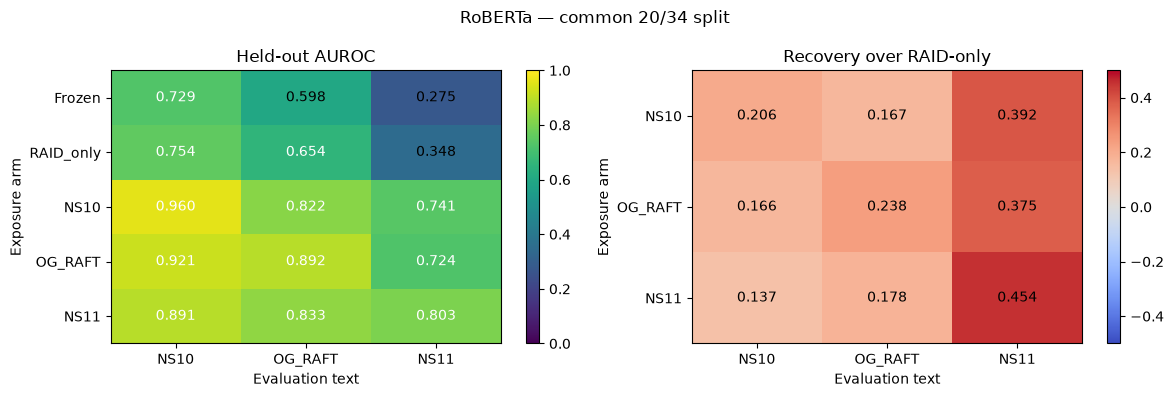

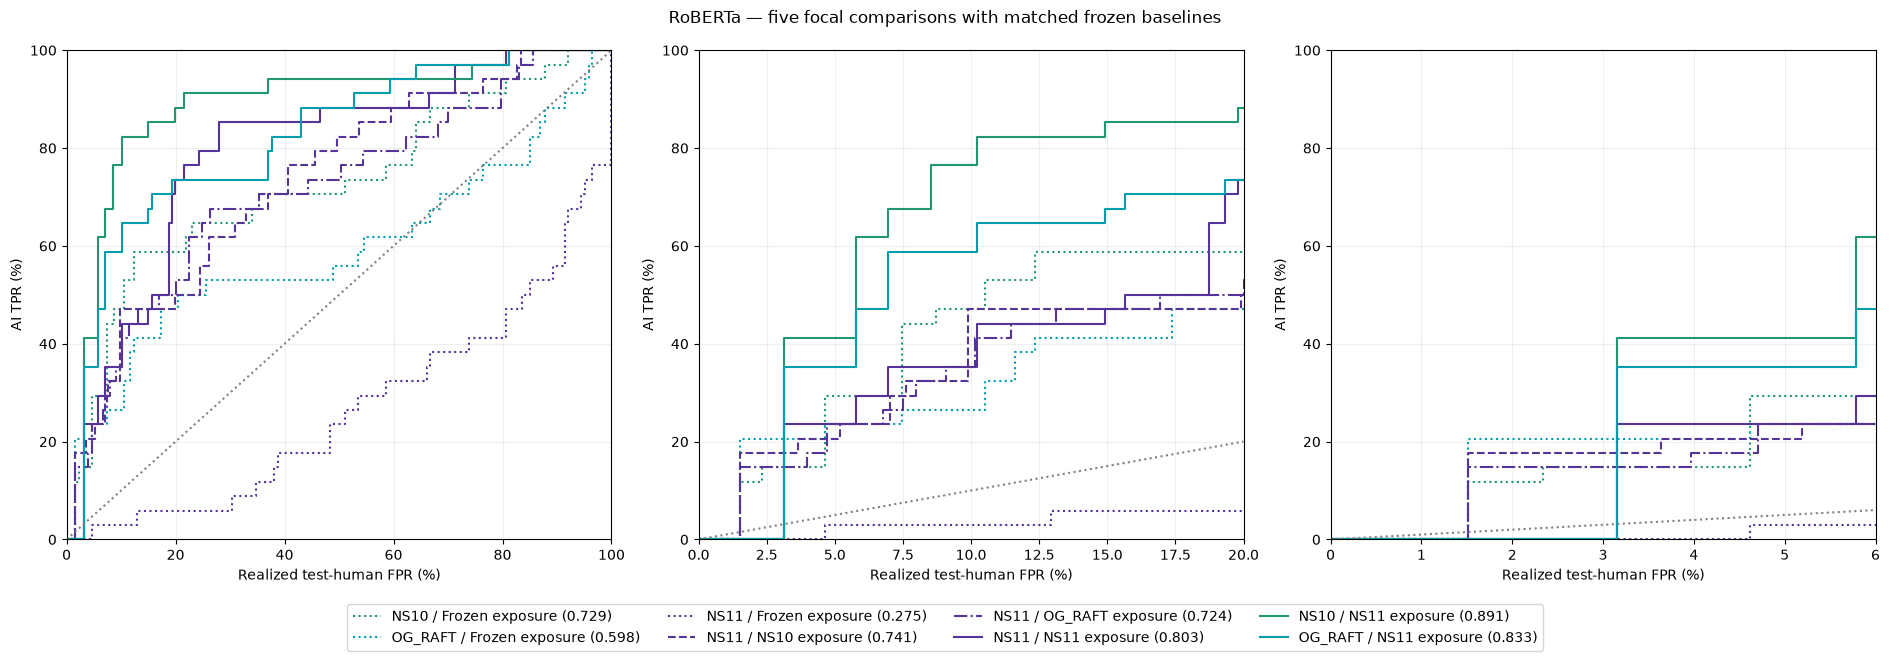

In [9]:
def run_roberta():
 from transformers import AutoTokenizer,AutoModelForSequenceClassification,Trainer,DataCollatorWithPadding,set_seed
 from transformers.trainer_utils import get_last_checkpoint
 import importlib.metadata
 det='RoBERTa';folder=OUT/det;folder.mkdir(parents=True,exist_ok=True)
 frozen=R/'C07b_RoBERTa_RAID_OG_NS10_v1/best_model';ref=frozen.parent/'adaptation20_34_seed20260923'
 argpath=next((p for p in [ref/'best_model/training_args.bin',*sorted((ref/'training').glob('checkpoint-*/training_args.bin'))] if p.exists()),None)
 assert argpath is not None,'Restore C07b adaptation training_args.bin to preserve the original adaptation method.'
 args=torch.load(argpath,map_location='cpu',weights_only=False)
 assert args.load_best_model_at_end and args.bf16 and not args.fp16
 tok=AutoTokenizer.from_pretrained(frozen,use_fast=True);tok.truncation_side='right'
 env=dict(globals());env.update(OUT=folder,FROZEN=frozen,tok=tok,reference_args=args,va=validation,write_json=atomic_json,AutoModelForSequenceClassification=AutoModelForSequenceClassification,Trainer=Trainer,DataCollatorWithPadding=DataCollatorWithPadding,set_seed=set_seed,get_last_checkpoint=get_last_checkpoint,RUNTIME={k:importlib.metadata.version(k) for k in ['torch','transformers','accelerate']})
 exec(ROBERTA_SOURCE,env)
 old=OLD[det];proto=read_json(old/'protocol.json');fp=env['fingerprint'](frozen)
 compatible=bool(proto and proto.get('split')==split and proto.get('frozen')==fp and proto.get('adaptation_args_sha')==file_sha(argpath))
 try:
  for d in DEFENDERS:
   cp=frozen
   if d!='Frozen':
    fit=train.copy() if d=='RAID_only' else pd.concat([train,frames[d].loc[frames[d].case_id.isin(chosen)]],ignore_index=True)
    olddir=old/'adaptation'/d;candidate=olddir/'best_model';done=read_json(olddir/'done.json')
    expected=fit[['source_id','label','text_sha']].to_dict('records')
    if compatible and done and candidate.exists() and read_json(olddir/'training_inputs.json')==expected:
     assert done['weights']==env['fingerprint'](candidate);cp=candidate;print(det,d,': reusing C08b model')
    else:cp=env['train_continuation'](d,fit)
   result=env['score_checkpoint'](cp,evaldocs,'C09b '+d)
   save_scores(det,d,evaldocs,result.AI_score.to_numpy(),dict(checkpoint=str(cp),weights=env['fingerprint'](cp),runtime=env['RUNTIME']))
 finally:env.clear();release()
 return summarize(det)
with run_lock():run_roberta()


## WaveDetect — reuse C08d full-model continuations
The saved C08d training contract and input identities govern reuse. Missing models use its three-epoch stage-2 continuation, learning rate 1e-5, logical batch 8 and microbatch 1. Only one model resides on GPU. This stage may be the longest if adapted checkpoints are missing locally.

In [10]:
WAVE_SOURCE = 'def atomic(path,writer):\n    path=Path(path); fd,tmp=tempfile.mkstemp(dir=path.parent,prefix=path.name+\'.\',suffix=\'.tmp\')\n    try:\n        with os.fdopen(fd,\'wb\') as f: writer(f); f.flush(); os.fsync(f.fileno())\n        os.replace(tmp,path)\n    finally:\n        if os.path.exists(tmp): os.unlink(tmp)\n\ndef save_json(x,p): atomic(p,lambda f:f.write(json.dumps(x,sort_keys=True,indent=2,allow_nan=False).encode()))\n\ndef save_csv(df,p): atomic(p,lambda f:f.write(df.to_csv(index=False).encode()))\n\ndef save_torch(x,p): atomic(p,lambda f:torch.save(x,f))\n\ndef freeze(x,p):\n    if p.exists(): assert json.loads(p.read_text())==x, f\'Contract changed: use a new OUT directory ({p}).\'\n    else: save_json(x,p)\n\ndef encode(text):\n    key=text_sha(text); path=OUT/\'tokens\'/(key+\'.pt\')\n    if path.exists():\n        obj=torch.load(path,map_location=\'cpu\',weights_only=True)\n        assert obj[\'contract\']==CONTRACT_SHA\n        return obj\n    full=tokenizer(str(text),add_special_tokens=True)[\'input_ids\']\n    assert len(full)>=2, \'Document has fewer than two tokens\'\n    ids=full[:MAX_LENGTH]; n=len(ids)\n    obj=dict(contract=CONTRACT_SHA,input_ids=torch.tensor(ids+[tokenizer.pad_token_id]*(MAX_LENGTH-n)),\n             attention_mask=torch.tensor([1]*n+[0]*(MAX_LENGTH-n)),tokens_total=len(full),tokens_used=n,\n             truncated=len(full)>MAX_LENGTH)\n    save_torch(obj,path); return obj\n\nclass WaveletTransform(nn.Module):\n    """\n    Differentiable continuous wavelet transform (Morlet basis) with padding,\n    cropping, and reconstruction.\n    Inputs:\n        token_probs (B, T)\n        attention_mask (B, T) — optional but recommended\n    Output:\n        wavelet_spectrum (B, 1, num_scales, T)\n    """\n    def __init__(self, wavelet="morl", num_scales=32, kernel_size=128):\n        super().__init__()\n        assert wavelet == "morl", "Only Morlet wavelet is supported at this time"\n        self.num_scales = num_scales\n        self.kernel_size = kernel_size\n\n        # Time axis in [-2, 2]\n        self.register_buffer("time", torch.linspace(-2, 2, steps=kernel_size))\n        self.sigma = 1.0\n        self.freq0 = 5.0\n        self.register_buffer("scales", torch.linspace(1.0, num_scales, num_scales))\n\n    def morlet_wavelet(self, scale):\n        t = self.time / scale\n        wave = torch.exp(-0.5 * (t / self.sigma) ** 2) * torch.cos(2 * math.pi * self.freq0 * t)\n        wave = wave / (wave.abs().sum() + 1e-6)\n        return wave.view(1, 1, -1)\n\n    def forward(self, token_probs: torch.FloatTensor, attention_mask: torch.FloatTensor = None):\n        """\n        token_probs: (B, T)\n        attention_mask: (B, T)\n        return: wavelet_spectrum (B, 1, num_scales, T)\n        """\n        B, T = token_probs.shape\n        device = token_probs.device\n\n        if attention_mask is not None:\n            # Compute the valid sequence length for each sample\n            valid_lengths = attention_mask.sum(dim=1).long()\n        else:\n            valid_lengths = torch.full((B,), T, dtype=torch.long, device=device)\n\n        # ========== Wavelet transform ==========\n        responses = []\n        for i in range(B):\n            valid_len = valid_lengths[i].item()\n            x_valid = token_probs[i, :valid_len].unsqueeze(0).unsqueeze(0)  # (1, 1, valid_len)\n            res_list = []\n            for s in self.scales:\n                kernel = self.morlet_wavelet(s.to(device)).to(x_valid.dtype)\n                pad = self.kernel_size // 2\n                conv_real = torch.nn.functional.conv1d(x_valid, kernel, padding=pad)\n                res_list.append(conv_real)\n            # Stack responses into shape (1, 1, num_scales, valid_len)\n            res = torch.stack(res_list, dim=2)\n            \n            # Restore the original length T by padding zeros on the right\n            if valid_len < T:\n                pad_size = T - valid_len\n                res = torch.nn.functional.pad(res, (0, pad_size))\n            responses.append(res)\n\n        responses = torch.cat(responses, dim=0)  # (B, 1, num_scales, T)\n        energy = responses.abs()\n\n        return energy\n\nclass RaidWaveDetect(nn.Module):\n    def __init__(self):\n        super().__init__()\n        self.qwen_model=AutoModelForCausalLM.from_pretrained(snapshot,torch_dtype=torch.bfloat16,\n                                                          attn_implementation=\'sdpa\')\n        self.qwen_model.config.use_cache=False\n        self.qwen_model.gradient_checkpointing_enable(gradient_checkpointing_kwargs={\'use_reentrant\':False})\n        self.wavelet=WaveletTransform(num_scales=16,kernel_size=128)\n        cfg=ResNetConfig(num_channels=3,embedding_size=64,hidden_sizes=[64,128,256,512],\n                         depths=[2,2,2,2],layer_type=\'basic\',hidden_act=\'relu\',downsample_in_first_stage=False)\n        self.cnn=ResNetModel(cfg)\n        self.classifier=nn.Linear(512,2)\n        self.stage=1\n    def set_stage(self,stage):\n        self.stage=stage\n        self.qwen_model.requires_grad_(stage==2)\n    def train(self,mode=True):\n        super().train(mode)\n        if self.stage==1: self.qwen_model.eval()\n        return self\n    def projected_probs(self,h,y):\n        logits=self.qwen_model.lm_head(h).float()\n        return logits.log_softmax(-1).gather(-1,y.unsqueeze(-1)).squeeze(-1).exp()\n    def forward(self,input_ids,attention_mask):\n        with torch.set_grad_enabled(self.training and self.stage==2):\n            h=self.qwen_model.model(input_ids=input_ids,attention_mask=attention_mask,\n                                    use_cache=False,return_dict=True).last_hidden_state[:,:-1]\n            target=input_ids[:,1:]\n            chunks=[]\n            for start in range(0,h.shape[1],64):\n                args=(h[:,start:start+64],target[:,start:start+64])\n                if self.training and self.stage==2:\n                    prob=checkpoint(self.projected_probs,*args,use_reentrant=False)\n                else: prob=self.projected_probs(*args)\n                chunks.append(prob)\n            mask=attention_mask[:,:-1]\n            probs=torch.cat(chunks,dim=1)*mask\n        spectrum=self.wavelet(probs,mask).repeat(1,3,1,1)\n        out=self.cnn(spectrum,return_dict=True).last_hidden_state.mean(dim=(2,3))\n        return self.classifier(out)\n\ndef load_frozen():\n obj=torch.load(FROZEN,map_location=\'cpu\',weights_only=False)\n assert obj[\'contract\']==OLD_SHA\n model.load_state_dict(obj[\'model\']);model.set_stage(2);model.eval()\n del obj;gc.collect();torch.cuda.empty_cache()\n\ndef batch_inputs(frame):\n    records=[encode(t) for t in frame.text]\n    return {k:torch.stack([r[k] for r in records]).to(DEVICE) for k in [\'input_ids\',\'attention_mask\']}\n\ndef loss_coeff(labels):\n    # Exact authors\' loss: sum_c [N/(2*n_c)] * mean(losses in class c).\n    # This is not the usual sample-weighted CE. Compute once per logical batch.\n    n=len(labels);counts=np.bincount(np.asarray(labels,int),minlength=2)\n    return np.array([n/(2*counts[int(y)]**2) for y in labels],dtype=np.float32)\n\n@torch.no_grad()\ndef validation_loss():\n    model.eval(); values=[]\n    for start in range(0,len(va),BATCH):\n        group=va.iloc[start:start+BATCH]; coeff=loss_coeff(group.label.to_numpy()); total=0.\n        for j in range(0,len(group),MICROBATCH):\n            part=group.iloc[j:j+MICROBATCH]\n            with torch.autocast(\'cuda\',dtype=torch.bfloat16): logits=model(**batch_inputs(part))\n            ce=nn.functional.cross_entropy(logits.float(),torch.tensor(part.label.to_numpy(),device=DEVICE),reduction=\'none\')\n            total+=float((ce*torch.tensor(coeff[j:j+len(part)],device=DEVICE)).sum())\n        values.append(total)\n    return float(np.mean(values))\n\n@torch.no_grad()\ndef score_frame(frame,name,folder,model_key):\n folder.mkdir(parents=True,exist_ok=True);cache=OUT/\'scores\'\n model.eval();rows=[]\n for r in tqdm(frame.to_dict(\'records\'),desc=name):\n  text=r.pop(\'text\');sha=text_sha(text);key=text_sha(CONTRACT_SHA+model_key+sha)\n  p=cache/(key+\'.json\')\n  if p.exists():\n   z=json.loads(p.read_text());assert z[\'text_sha\']==sha and z[\'model_key\']==model_key\n  else:\n   rec=encode(text)\n   with torch.autocast(\'cuda\',dtype=torch.bfloat16):\n    logits=model(**{k:rec[k].unsqueeze(0).to(DEVICE) for k in [\'input_ids\',\'attention_mask\']})\n   value=float(logits.float().softmax(-1)[0,1]);assert np.isfinite(value)\n   z=dict(text_sha=sha,model_key=model_key,AI_score=value,tokens_total=rec[\'tokens_total\'],\n          tokens_used=rec[\'tokens_used\'],truncated=rec[\'truncated\'])\n   save_json(z,p)\n  rows.append({**r,**z})\n out=pd.DataFrame(rows);save_csv(out,folder/(name+\'_scores.csv\'));return out\n\ndef continue_model(frame,folder):\n global tr\n tr=frame.sort_values(\'source_id\',kind=\'stable\').reset_index(drop=True)\n folder.mkdir(parents=True,exist_ok=True)\n run=dict(contract=CONTRACT_SHA,training=[dict(source_id=r.source_id,label=int(r.label),text_sha=text_sha(r.text)) for r in tr.itertuples()])\n freeze(run,folder/\'training_contract.json\')\n RUN_SHA=text_sha(json.dumps(run,sort_keys=True))\n LATEST=folder/\'latest.pt\';FINAL=folder/\'best.pt\'\n load_frozen()\n random.seed(SEED);np.random.seed(SEED);torch.manual_seed(SEED);torch.cuda.manual_seed_all(SEED)\n def cpu_state(m): return {k:v.detach().cpu().clone() for k,v in m.state_dict().items()}\n def rng_state():\n     return dict(python=random.getstate(),numpy=np.random.get_state(),cpu=torch.get_rng_state(),cuda=torch.cuda.get_rng_state_all())\n def restore_rng(r):\n     random.setstate(r[\'python\']);np.random.set_state(r[\'numpy\']);torch.set_rng_state(r[\'cpu\']);torch.cuda.set_rng_state_all(r[\'cuda\'])\n\n if FINAL.exists():\n     final=torch.load(FINAL,map_location=\'cpu\',weights_only=False)\n     assert final[\'contract\']==RUN_SHA\n     model.load_state_dict(final[\'model\']);model.set_stage(2);model.eval()\n     print(\'Reused completed continuation:\',folder.name)\n     del final\n else:\n     # Trust only checkpoints created by this notebook in this output directory.\n     resume=torch.load(LATEST,map_location=\'cpu\',weights_only=False) if LATEST.exists() else None\n     if resume:\n         assert resume[\'contract\']==RUN_SHA\n         model.load_state_dict(resume[\'model\'])\n     history=resume[\'history\'] if resume else []\n     best=resume[\'best\'] if resume else None\n     best_loss=resume[\'best_loss\'] if resume else float(\'inf\')\n     start_stage=resume[\'stage\'] if resume else 2\n     for stage in range(start_stage,3):\n         model.set_stage(stage)\n         optimizer=torch.optim.AdamW([p for p in model.parameters() if p.requires_grad],lr=LRS[stage-1],\n                                     eps=1e-8,weight_decay=.01,foreach=False)\n         steps_per_epoch=math.ceil(len(tr)/BATCH)\n         total_steps=steps_per_epoch*EPOCHS[stage-1]\n         scheduler=torch.optim.lr_scheduler.LambdaLR(optimizer,lambda s:max(0.,1-s/total_steps))\n         epoch0=0;cursor0=0;updates=0;running=0.;seen=0\n         if resume and resume[\'stage\']==stage:\n             optimizer.load_state_dict(resume[\'optimizer\']);scheduler.load_state_dict(resume[\'scheduler\'])\n             epoch0=resume[\'epoch\'];cursor0=resume[\'cursor\'];updates=resume[\'updates\']\n             running=resume[\'running\'];seen=resume[\'seen\'];restore_rng(resume[\'rng\'])\n             del resume;resume=None;gc.collect()\n         def checkpoint_training(epoch,cursor):\n             save_torch(dict(contract=RUN_SHA,model=model.state_dict(),optimizer=optimizer.state_dict(),\n                 scheduler=scheduler.state_dict(),stage=stage,epoch=epoch,cursor=cursor,updates=updates,\n                 running=running,seen=seen,rng=rng_state(),history=history,best=best,best_loss=best_loss),LATEST)\n         for epoch in range(epoch0,EPOCHS[stage-1]):\n             order=np.random.default_rng(SEED+1000*stage+epoch).permutation(len(tr))\n             begin=cursor0 if epoch==epoch0 else 0\n             model.train();optimizer.zero_grad(set_to_none=True)\n             bar=tqdm(range(begin,len(tr),BATCH),total=math.ceil((len(tr)-begin)/BATCH),\n                      desc=f\'Stage {stage}, epoch {epoch+1}/{EPOCHS[stage-1]}\')\n             for pos in bar:\n                 group=tr.iloc[order[pos:pos+BATCH]]; coeff=loss_coeff(group.label.to_numpy());batch_loss=0.\n                 for j in range(0,len(group),MICROBATCH):\n                     part=group.iloc[j:j+MICROBATCH]\n                     with torch.autocast(\'cuda\',dtype=torch.bfloat16): logits=model(**batch_inputs(part))\n                     ce=nn.functional.cross_entropy(logits.float(),torch.tensor(part.label.to_numpy(),device=DEVICE),reduction=\'none\')\n                     loss=(ce*torch.tensor(coeff[j:j+len(part)],device=DEVICE)).sum()\n                     assert torch.isfinite(loss), \'Nonfinite loss; last checkpoint retained.\'\n                     loss.backward();batch_loss+=float(loss.detach())\n                 norm=torch.nn.utils.clip_grad_norm_(model.parameters(),1.,error_if_nonfinite=True)\n                 optimizer.step();scheduler.step();optimizer.zero_grad(set_to_none=True)\n                 updates+=1;running+=batch_loss;seen+=1\n                 if updates%SAVE_EVERY==0: checkpoint_training(epoch,min(pos+BATCH,len(tr)))\n                 bar.set_postfix(loss=round(batch_loss,4),lr=f\'{scheduler.get_last_lr()[0]:.2g}\')\n             val=validation_loss()\n             assert np.isfinite(val)\n             history.append(dict(stage=stage,epoch=epoch+1,train_loss=running/max(1,seen),validation_loss=val))\n             if stage==2 and val<best_loss: best_loss=val;best=cpu_state(model)\n             display(pd.DataFrame(history).tail(1))\n             running=0.;seen=0;checkpoint_training(epoch+1,0)\n             save_csv(pd.DataFrame(history),folder/\'training_history.csv\')\n             cursor0=0\n         del optimizer,scheduler;gc.collect();torch.cuda.empty_cache()\n     assert best is not None\n     save_torch(dict(contract=RUN_SHA,model=best,best_validation_loss=best_loss,history=history),FINAL)\n     model.load_state_dict(best);model.set_stage(2);model.eval()\n     del best;gc.collect();torch.cuda.empty_cache()\n     print(\'Training complete. Selected stage-2 validation loss:\',best_loss)\n return FINAL'


all_three_arms: 100%|████████████████████████████████████████████████████████████████████████████████| 375/375 [00:40<00:00,  9.19it/s]


WaveDetect RAID_only : reusing C08d model


all_three_arms: 100%|████████████████████████████████████████████████████████████████████████████████| 375/375 [00:35<00:00, 10.43it/s]


WaveDetect NS10 : reusing C08d model


all_three_arms: 100%|████████████████████████████████████████████████████████████████████████████████| 375/375 [00:36<00:00, 10.35it/s]


...

all_three_arms: 100%|████████████████████████████████████████████████████████████████████████████████| 375/375 [00:37<00:00,  9.99it/s]


WaveDetect NS11 : reusing C08d model


all_three_arms: 100%|████████████████████████████████████████████████████████████████████████████████| 375/375 [00:36<00:00, 10.23it/s]


arm,NS10,OG_RAFT,NS11
exposure,,,
Frozen,0.5692,0.6159,0.2824
RAID_only,0.5782,0.6477,0.2810
NS10,0.5392,0.6357,0.3514
OG_RAFT,0.5302,0.6352,0.3538
NS11,0.5338,0.6320,0.3533


,detector,contrast,delta_AUROC,ci_low,ci_high
18,WaveDetect,RAFT vs NS10 exposure on NS11,0.00239,-0.00648,0.01073
19,WaveDetect,OG_RAFT exposure: recovery on NS11 minus recov...,0.12079,0.06092,0.18101
20,WaveDetect,NS11 exposure: recovery on OG_RAFT minus recov...,0.02869,-0.04417,0.09891


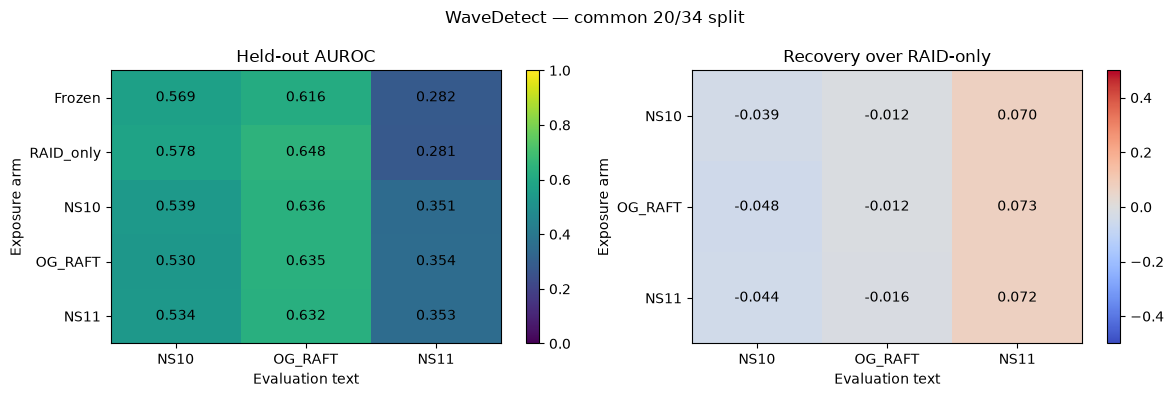

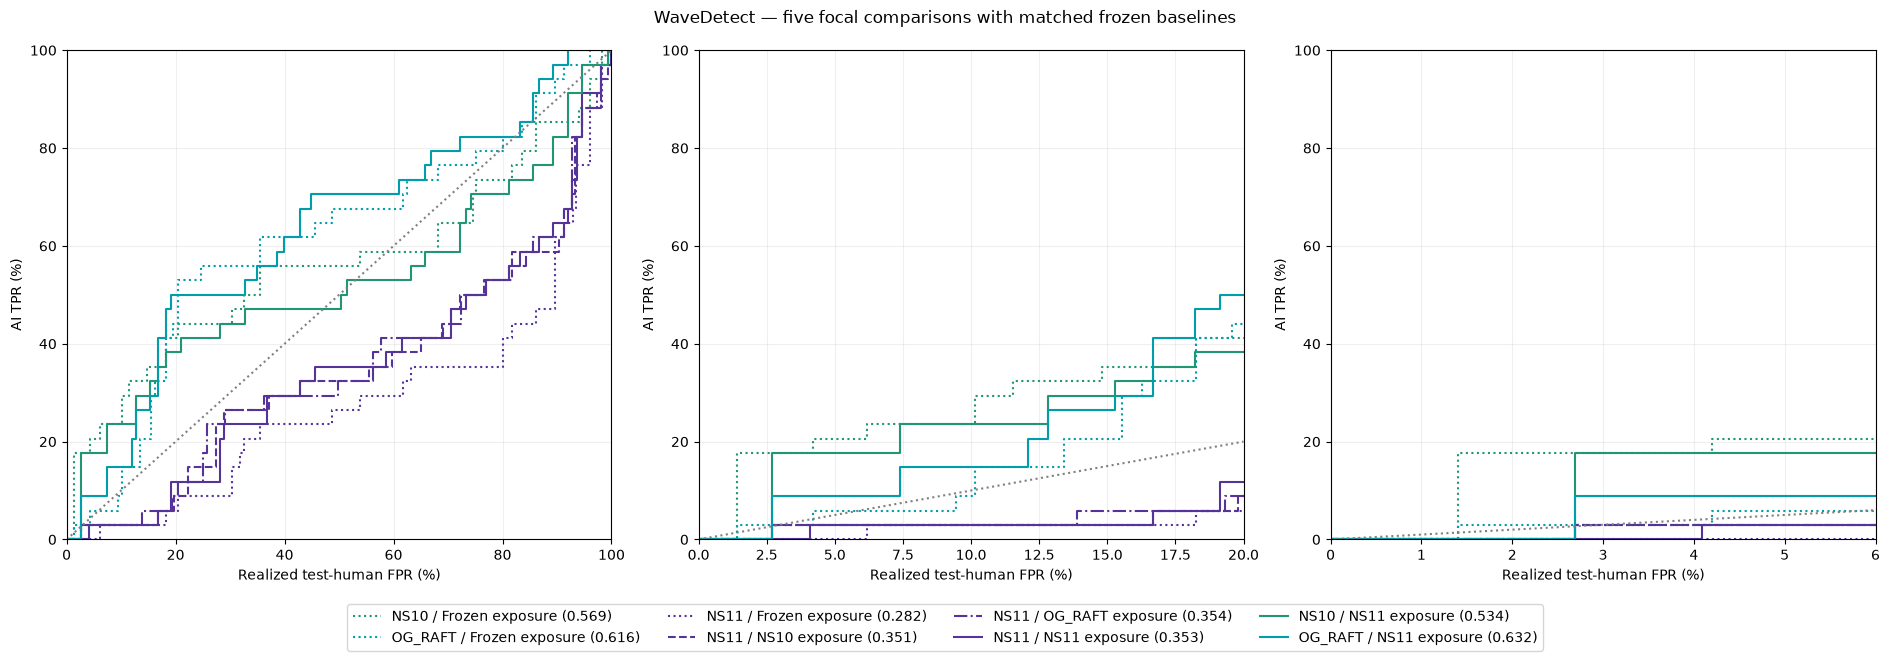

In [11]:
def run_wave():
 import torch.nn as nn
 from torch.utils.checkpoint import checkpoint
 from transformers import AutoModelForCausalLM,AutoTokenizer,ResNetConfig,ResNetModel
 from huggingface_hub import snapshot_download
 from tqdm.auto import tqdm
 det='WaveDetect';folder=OUT/det;folder.mkdir(parents=True,exist_ok=True)
 for sub in ['tokens','scores']:(folder/sub).mkdir(exist_ok=True)
 c07=R/'C07_WaveDetect_RAID_OG_NS10_v1';frozen=c07/'wavedetect_raid_best.pt'
 rev=read_json(c07/'base_revision.json')['revision'];snapshot=Path(snapshot_download('Qwen/Qwen2.5-0.5B',revision=rev))
 tokenizer=AutoTokenizer.from_pretrained(snapshot);tokenizer.padding_side='right'
 if tokenizer.pad_token_id is None:tokenizer.pad_token=tokenizer.eos_token
 old_contract=read_json(c07/'contract.json');oldsha=sha(json.dumps(old_contract,sort_keys=True))
 contract=dict(version='C08d_v1',frozen_sha=file_sha(frozen),original_contract=old_contract,torch=str(torch.__version__),transformers=transformers.__version__,max_length=1024,adaptation_epochs=3,adaptation_lr=1e-5,logical_batch=8,microbatch=1,seed=20260922,selection='minimum original RAID validation loss',split=split,raid_texts=sha(json.dumps(raid[['source_id','split','label','text_sha']].to_dict('records'),sort_keys=True)))
 # A changed runtime triggers a separate C09b fit; never modifies C08d artifacts.
 freeze(folder/'contract.json',contract);cs=sha(json.dumps(contract,sort_keys=True))
 env=dict(globals());env.update(OUT=folder,FROZEN=frozen,OLD_SHA=oldsha,CONTRACT_SHA=cs,SEED=20260922,DEVICE=torch.device('cuda'),MAX_LENGTH=1024,MICROBATCH=1,BATCH=8,EPOCHS=(3,3),LRS=(1e-3,1e-5),SAVE_EVERY=10,snapshot=snapshot,tokenizer=tokenizer,va=validation,tr=train,nn=nn,checkpoint=checkpoint,AutoModelForCausalLM=AutoModelForCausalLM,ResNetConfig=ResNetConfig,ResNetModel=ResNetModel,tqdm=tqdm,text_sha=sha)
 exec(WAVE_SOURCE,env);env['model']=env['RaidWaveDetect']().to('cuda')
 try:
  for d in DEFENDERS:
   cp=frozen
   if d=='Frozen':env['load_frozen']()
   else:
    fit=train.copy() if d=='RAID_only' else pd.concat([train,frames[d].loc[frames[d].case_id.isin(chosen)]],ignore_index=True)
    ordered=fit.sort_values('source_id',kind='stable').reset_index(drop=True)
    run=dict(contract=cs,training=[dict(source_id=r.source_id,label=int(r.label),text_sha=sha(r.text)) for r in ordered.itertuples()])
    olddir=OLD[det]/('RAID_only_continuation' if d=='RAID_only' else d);candidate=olddir/'best.pt'
    if candidate.exists() and read_json(olddir/'training_contract.json')==run:
     obj=torch.load(candidate,map_location='cpu',weights_only=False);assert obj['contract']==sha(json.dumps(run,sort_keys=True))
     env['model'].load_state_dict(obj['model']);env['model'].set_stage(2);env['model'].eval();del obj;cp=candidate;print(det,d,': reusing C08d model')
    else:cp=env['continue_model'](fit,folder/'adaptation'/d)
   result=env['score_frame'](evaldocs.copy(),'all_three_arms',folder/d,file_sha(cp))
   save_scores(det,d,evaldocs,result.AI_score.to_numpy(),dict(checkpoint=str(cp),weights=file_sha(cp),contract=contract))
 finally:
  env.pop('model',None);env.clear();release()
 return summarize(det)
with run_lock():run_wave()


## Combined results and hypothesis checks
Positive recovery means the defender became better at discrimination. The transfer-selectivity contrasts compare recovery against the same RAID-only control. Inspect the full matrix and operating points alongside AUROC: score shifts alone and very low original-orientation AUROC do not establish human-distribution matching. The experiment does not fine-tune the Falcon pair or change Ghostbuster/GLTR feature representations, so its adaptation scope differs from full neural continuation.

In [12]:
missing=[d for d in DETECTORS if not (OUT/d/'summary.csv').exists()]
assert not missing,'Run remaining detector cells: '+', '.join(missing)
summary=pd.concat([pd.read_csv(OUT/d/'summary.csv') for d in DETECTORS],ignore_index=True)
changes=pd.concat([pd.read_csv(OUT/d/'paired_contrasts.csv') for d in DETECTORS],ignore_index=True)
focal=summary.loc[[tuple(x) in FOCAL for x in summary[['exposure','arm']].to_numpy()]].copy()
csv(summary,OUT/'all_detectors_full_matrix.csv');csv(changes,OUT/'all_detectors_paired_contrasts.csv');csv(focal,OUT/'five_pairs_all_detectors.csv')
display(focal.pivot(index=['exposure','arm'],columns='detector',values='AUROC').round(4))
display(changes.loc[changes.contrast.str.contains('recovery on|RAFT vs NS10')].round(5))
print('Saved all scores, identities, readouts/checkpoints, matrices, contrasts and staircase plots under',OUT)


detector          Binoculars    GLTR  Ghostbuster  RoBERTa  WaveDetect
exposure arm                                                          
NS10     NS11         0.4587  0.1085       0.2460   0.7406      0.3514
NS11     NS10         0.6946  0.4984       0.6136   0.8911      0.5338
         NS11         0.5171  0.1536       0.4077   0.8025      0.3533
         OG_RAFT      0.7359  0.4520       0.4412   0.8329      0.6320
OG_RAFT  NS11         0.4635  0.1297       0.3003   0.7237      0.3538

,detector,contrast,delta_AUROC,ci_low,ci_high
18,Ghostbuster,RAFT vs NS10 exposure on NS11,0.05429,0.03286,0.07711
19,Ghostbuster,OG_RAFT exposure: recovery on NS11 minus recov...,0.08666,0.03663,0.13769
20,Ghostbuster,NS11 exposure: recovery on OG_RAFT minus recov...,0.04198,-0.02552,0.10860
39,Binoculars,RAFT vs NS10 exposure on NS11,0.00478,0.00242,0.00754
40,Binoculars,OG_RAFT exposure: recovery on NS11 minus recov...,0.01313,0.00492,0.02177
41,Binoculars,NS11 exposure: recovery on OG_RAFT minus recov...,0.00772,-0.00729,0.02302
60,GLTR,RAFT vs NS10 exposure on NS11,0.02120,0.01394,0.02913
61,GLTR,OG_RAFT exposure: recovery on NS11 minus recov...,0.03150,0.01768,0.04569
62,GLTR,NS11 exposure: recovery on OG_RAFT minus recov...,0.10620,0.07187,0.13924
81,RoBERTa,RAFT vs NS10 exposure on NS11,-0.01695,-0.06357,0.02713


Saved all scores, identities, readouts/checkpoints, matrices, contrasts and staircase plots under ../results/causal/C09b_Cross_Attack_Adaptation_20_34_v1
